# Proyek Akhir Praktikum Data Science
## Prediksi Niat Pembelian Pengunjung Toko Online Berdasarkan Perilaku Sesi
**Program Studi Informatika - Fakultas Teknik Industri**  
**Universitas Pembangunan Nasional "Veteran" Yogyakarta**  
**Semester Ganjil 2026/2027**

---

### Informasi Kelompok
- **Nomor Kelompok**: 61
- **Nama Kelompok**: Mau ARGON atau ASTRA?
- **Kelas**: IF-H

### Anggota Kelompok
| No | NIM | Nama Mahasiswa | Kelas |
|:--:|:---:|:---------------|:-----:|
| 1 | 123240135 | Oktavian Prasetya Adi | IF-H |
| 2 | 123240019 | Marvel Valensiano | IF-H |
| 3 | 123240069 | Adhafa Joan Putranto | IF-H |
| 4 | 123240160 | Dzaki Ghatfaan Abhipraya | IF-H |

---

### Sistematika Notebook:
1. **Business Understanding** (Latar Belakang, Identifikasi Masalah, Tujuan Proyek, Metrik Keberhasilan)
2. **Data Gathering** (Import Library, Load Dataset, Inspeksi Struktur & Dimensi Awal)
3. **Exploratory Data Analysis (EDA)** (Statistik Deskriptif, Analisis Target Imbalance, Visualisasi Distribusi Fitur, Analisis Hubungan Bivariate, Korelasi Heatmap)
4. **Data Cleaning** (Pengecekan Missing Value, Penanganan Duplikat, Deteksi & Analisis Outlier IQR)
5. **Data Preprocessing** (Feature Engineering, Categorical Encoding, Train-Test Split, Feature Scaling)


## 1. Business Understanding

### 1.1. Latar Belakang Bisnis
Dalam era perdagangan digital modern (*e-commerce*), situs web toko online menerima ribuan hingga jutaan kunjungan sesi pengguna setiap harinya. Namun, sebagian besar pengunjung hanya sekadar melihat-lihat katalog produk (*window shopping*) atau langsung keluar dari situs (*bounce*) tanpa menyelesaikan transaksi pembelian (*checkout*). Rata-rata rasio konversi (*conversion rate*) global pada industri e-commerce umumnya berkisar antara 2% hingga 4%.

Ketidakmampuan dalam mendeteksi dan memahami intensi pengunjung secara *real-time* mengakibatkan tim pemasaran (*marketing*) dan pengembang sistem (*product development*) kesulitan dalam memberikan intervensi proaktif—seperti pemberian promosi personal, diskon terarah, atau dukungan obrolan langsung (*live support*)—kepada pengunjung yang sebenarnya memiliki potensi tinggi untuk melakukan transaksi.

### 1.2. Identifikasi & Rumusan Masalah
Berdasarkan latar belakang tersebut, permasalahan yang dihadapi dirumuskan sebagai berikut:
1. Bagaimana profil dan karakteristik navigasi sesi pengunjung toko online (halaman yang dibuka, waktu kunjungan, dan indikator navigasi web)?
2. Fitur-fitur navigasi apa saja yang paling membedakan antara pengunjung yang berakhir melakukan pembelian (`Revenue = True`) dan yang tidak (`Revenue = False`)?
3. Bagaimana tahapan pembersihan (*data cleaning*) dan prapemrosesan (*preprocessing*) yang tepat agar dataset sesi pengguna bersih, terstandarisasi, dan siap untuk digunakan dalam pemodelan klasifikasi Machine Learning?

### 1.3. Tujuan Proyek
Tujuan yang ingin dicapai melalui analisis data ini meliputi:
1. Mengidentifikasi pola perilaku dan kebiasaan berselancar pengunjung toko online berdasarkan data sesi.
2. Menemukan faktor-faktor kunci (seperti `PageValues`, `BounceRates`, `ExitRates`, dan waktu sesi) yang berkorelasi kuat dengan niat pembelian.
3. Melakukan pembersihan data dari duplikasi dan anomali tanpa menghilangkan informasi penting, disimpan langsung ke dalam DataFrame.
4. Menyiapkan representasi fitur yang terstandarisasi melalui teknik *encoding*, *feature engineering*, dan *scaling* sesuai metodologi praktikum data science.

### 1.4. Metrik Keberhasilan Bisnis & Machine Learning
- **Dampak Bisnis**: Memberikan pemahaman komprehensif bagi pemilik toko online untuk mengoptimalkan halaman produk, mengurangi angka *bounce rate*, serta meningkatkan angka konversi penjualan (*revenue generation*).
- **Karakteristik & Metrik Machine Learning**: Karena dataset e-commerce pada umumnya memiliki ketimpangan kelas yang signifikan (*imbalanced dataset*, mayoritas pengunjung tidak membeli), metrik evaluasi model di masa mendatang tidak cukup hanya mengandalkan *Accuracy*, melainkan memerlukan metrik yang sensitif terhadap kelas minoritas positif, seperti **Precision**, **Recall**, **F1-Score**, dan **ROC-AUC Score**.


## 2. Data Gathering & Inspeksi Awal

Pada tahap ini, dilakukan pemuatan pustaka (*libraries*) standar yang digunakan dalam kegiatan praktikum, diikuti dengan pembacaan dataset ke dalam objek DataFrame pandas serta pemeriksaan struktur awal.

### 2.1. Informasi Sumber Dataset
- **Nama Dataset**: Online Shoppers Purchasing Intention Dataset
- **Sumber Data**: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
- **Sitasi**: C. Sakar & S. Polat (2019)
- **Jumlah Observasi**: 12.330 sesi penjelajahan
- **Jumlah Atribut**: 18 atribut (fitur sesi web, fitur temporal, spesifikasi perangkat, dan target `Revenue`)


In [1]:
# 1.1. Import Library Standar Praktikum
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk preprocessing dan machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Konfigurasi visualisasi agar rapi dan seragam
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

print("Library berhasil diimpor!")


Library berhasil diimpor!


### 2.2. Pemuatan Dataset (*Data Loading*)

In [2]:
# Membaca dataset CSV dari direktori data/ ke DataFrame df
df = pd.read_csv('data/online_shoppers_intention.csv')

# Menampilkan 5 baris pertama data
display(df.head())


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### 2.3. Inspeksi Struktur & Dimensi Data

In [3]:
# Menampilkan dimensi data (jumlah baris dan kolom)
print("Dimensi dataset (baris, kolom):", df.shape)

# Menampilkan ringkasan tipe data dan jumlah nilai non-null
df.info()


Dimensi dataset (baris, kolom): (12330, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 n

In [4]:
# Menampilkan daftar nama seluruh kolom
print("Daftar kolom dataset:")
print(df.columns.tolist())


Daftar kolom dataset:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


## 3. Exploratory Data Analysis (EDA)

Tahap analisis data eksploratif bertujuan untuk memahami karakteristik statistik data, pola persebaran, korelasi antartolak ukur sesi, serta hubungan antara fitur-fitur prediktor dengan variabel target (`Revenue`).

### 3.1. Statistik Deskriptif & Analisis Skewness
Statistik deskriptif menampilkan parameter pusat (Mean, Median) dan sebaran (Standar Deviasi, IQR, Min, Max).
- **Right-Skewed (Positif)**: Nilai $\text{Mean} > \text{Median}$ (menunjukkan ekor panjang di sisi kanan akibat adanya sejumlah kecil sesi dengan durasi atau jumlah halaman sangat tinggi).
- **Left-Skewed (Negatif)**: Nilai $\text{Mean} < \text{Median}$.
- **Simetris / Normal**: Nilai $\text{Mean} \approx \text{Median}$.


In [5]:
# Statistik deskriptif untuk fitur numerik
display(df.describe().round(2))


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00
mean,2.32,80.82,0.50,34.47,31.73,1194.75,0.02,0.04,5.89,0.06,2.12,2.36,3.15,4.07
std,3.32,176.78,1.27,140.75,44.48,1913.67,0.05,0.05,18.57,0.20,0.91,1.72,2.40,4.03
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00
25%,0.00,0.00,0.00,0.00,7.00,184.14,0.00,0.01,0.00,0.00,2.00,2.00,1.00,2.00
50%,1.00,7.50,0.00,0.00,18.00,598.94,0.00,0.03,0.00,0.00,2.00,2.00,3.00,2.00
75%,4.00,93.26,0.00,0.00,38.00,1464.16,0.02,0.05,0.00,0.00,3.00,2.00,4.00,4.00
max,27.00,3398.75,24.00,2549.38,705.00,63973.52,0.20,0.20,361.76,1.00,8.00,13.00,9.00,20.00


### 3.2. Analisis Distribusi Variabel Target (`Revenue`)
Langkah krusial pertama adalah memeriksa keseimbangan kelas pada variabel target `Revenue` (`True` = pengunjung melakukan transaksi pembelian, `False` = pengunjung tidak berbelanja).


Jumlah Observasi per Kelas Target:
Revenue
False    10422
True      1908
Name: count, dtype: int64

Persentase per Kelas Target (%):
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


C:\Users\oktav\AppData\Local\Temp\ipykernel_7820\1471784648.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Revenue', palette=['#d9534f', '#5cb85c'], ax=ax[0])


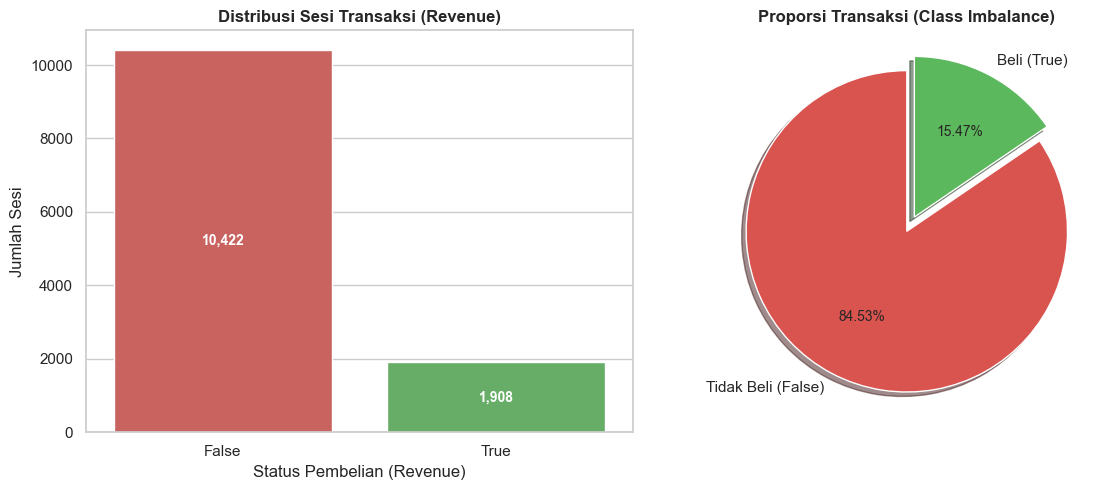

In [6]:
# Frekuensi dan persentase kelas target Revenue
revenue_counts = df['Revenue'].value_counts()
revenue_percent = df['Revenue'].value_counts(normalize=True) * 100

print("Jumlah Observasi per Kelas Target:")
print(revenue_counts)
print("\nPersentase per Kelas Target (%):")
print(revenue_percent.round(2))

# Visualisasi distribusi target (Countplot & Pie Chart)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Countplot
sns.countplot(data=df, x='Revenue', palette=['#d9534f', '#5cb85c'], ax=ax[0])
ax[0].set_title('Distribusi Sesi Transaksi (Revenue)', fontsize=12, fontweight='bold')
ax[0].set_xlabel('Status Pembelian (Revenue)')
ax[0].set_ylabel('Jumlah Sesi')
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height()):,}', 
                   (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold')

# Subplot 2: Pie Chart
labels = ['Tidak Beli (False)', 'Beli (True)']
ax[1].pie(revenue_counts, labels=labels, autopct='%1.2f%%', startangle=90, 
        colors=['#d9534f', '#5cb85c'], explode=(0, 0.1), shadow=True)
ax[1].set_title('Proporsi Transaksi (Class Imbalance)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


**Interpretasi Distribusi Target:**
- Dari total 12.330 sesi, terdapat 10.422 sesi (84,53%) di mana pengunjung tidak melakukan pembelian (`False`), dan hanya 1.908 sesi (15,47%) yang berujung pada transaksi (`True`).
- Dataset ini memiliki kondisi ketidakseimbangan kelas (*class imbalance*) moderat (~85:15), yang mencerminkan realitas industri e-commerce di mana mayoritas pengunjung hanya melakukan *browsing*.


### 3.3. Visualisasi Distribusi Fitur Numerik Utama (Univariate)
Berikut visualisasi distribusi frekuensi menggunakan histogram dan kurva estimasi densitas kernel (KDE) untuk memahami bentuk sebaran data.


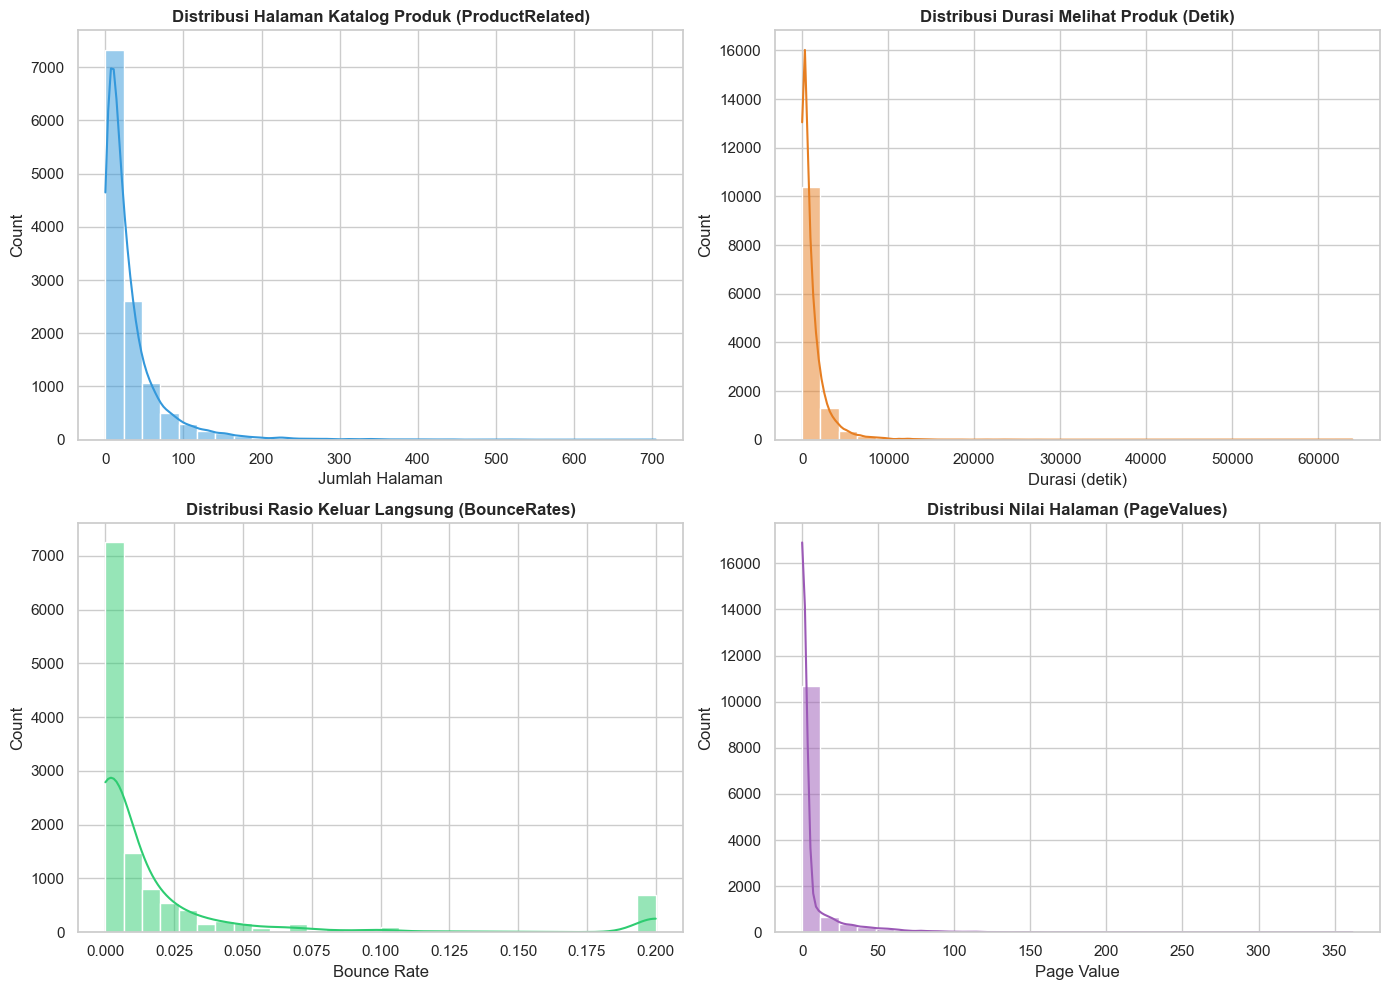

In [7]:
# Histogram & KDE untuk fitur numerik utama
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. ProductRelated
sns.histplot(df['ProductRelated'], kde=True, ax=axes[0, 0], color='#3498db', bins=30)
axes[0, 0].set_title('Distribusi Halaman Katalog Produk (ProductRelated)', fontweight='bold')
axes[0, 0].set_xlabel('Jumlah Halaman')

# 2. ProductRelated_Duration
sns.histplot(df['ProductRelated_Duration'], kde=True, ax=axes[0, 1], color='#e67e22', bins=30)
axes[0, 1].set_title('Distribusi Durasi Melihat Produk (Detik)', fontweight='bold')
axes[0, 1].set_xlabel('Durasi (detik)')

# 3. BounceRates
sns.histplot(df['BounceRates'], kde=True, ax=axes[1, 0], color='#2ecc71', bins=30)
axes[1, 0].set_title('Distribusi Rasio Keluar Langsung (BounceRates)', fontweight='bold')
axes[1, 0].set_xlabel('Bounce Rate')

# 4. PageValues
sns.histplot(df['PageValues'], kde=True, ax=axes[1, 1], color='#9b59b6', bins=30)
axes[1, 1].set_title('Distribusi Nilai Halaman (PageValues)', fontweight='bold')
axes[1, 1].set_xlabel('Page Value')

plt.tight_layout()
plt.show()


**Interpretasi Univariate:**
- Keempat fitur di atas memiliki sebaran yang sangat *right-skewed* (condong ke kanan dengan ekor panjang).
- Mayoritas pengunjung hanya membuka < 50 halaman katalog produk dengan durasi < 2.000 detik.
- Pada `PageValues`, sebagian besar sesi bernilai 0 (karena tidak ada halaman bernilai konversi yang dilewati), sedangkan sesi dengan `PageValues` tinggi adalah sesi yang sangat potensial melakukan transaksi.


### 3.4. Analisis Hubungan Fitur Sesi Web terhadap Pembelian (Bivariate)
Menganalisis bagaimana `PageValues` dan `ExitRates` membedakan antara pengunjung yang bertransaksi dengan yang tidak.


C:\Users\oktav\AppData\Local\Temp\ipykernel_7820\3559431237.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Revenue', y='PageValues', palette=['#d9534f', '#5cb85c'], ax=axes[0])
C:\Users\oktav\AppData\Local\Temp\ipykernel_7820\3559431237.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Revenue', y='ExitRates', palette=['#d9534f', '#5cb85c'], ax=axes[1])


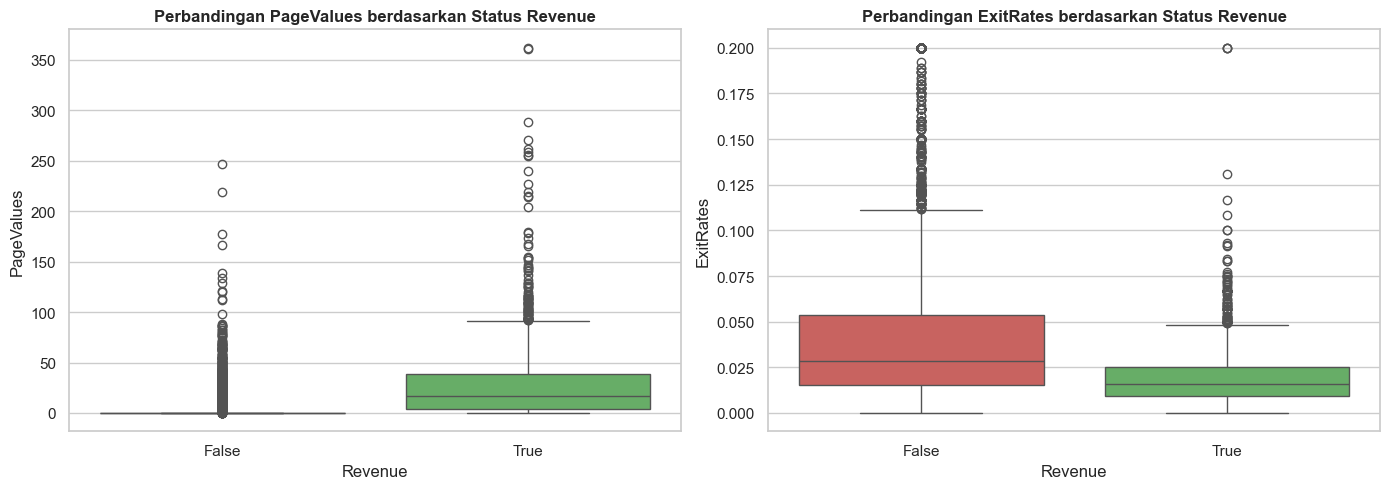

In [8]:
# Boxplot PageValues dan ExitRates dikelompokkan berdasarkan Revenue
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PageValues vs Revenue
sns.boxplot(data=df, x='Revenue', y='PageValues', palette=['#d9534f', '#5cb85c'], ax=axes[0])
axes[0].set_title('Perbandingan PageValues berdasarkan Status Revenue', fontweight='bold')
axes[0].set_xlabel('Revenue')
axes[0].set_ylabel('PageValues')

# ExitRates vs Revenue
sns.boxplot(data=df, x='Revenue', y='ExitRates', palette=['#d9534f', '#5cb85c'], ax=axes[1])
axes[1].set_title('Perbandingan ExitRates berdasarkan Status Revenue', fontweight='bold')
axes[1].set_xlabel('Revenue')
axes[1].set_ylabel('ExitRates')

plt.tight_layout()
plt.show()


### 3.5. Analisis Fitur Kategorikal (Bulan & Tipe Pengunjung)

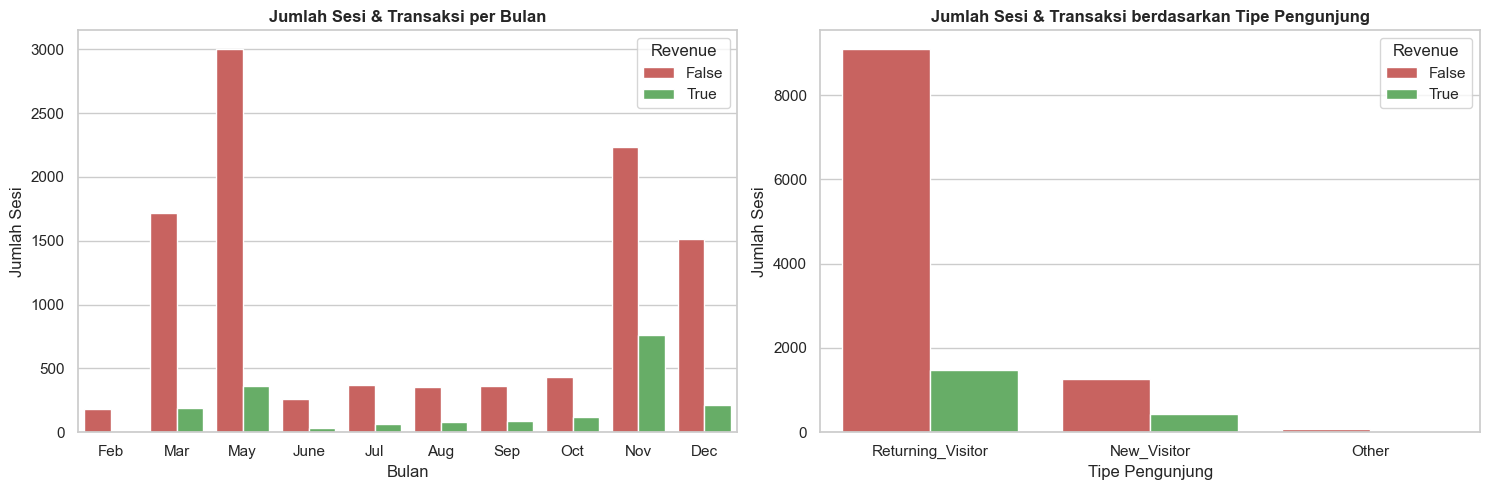

Tingkat Konversi Pembelian (%) per Bulan:


Revenue,False,True
Month,,
Feb,98.37,1.63
Mar,89.93,10.07
May,89.15,10.85
June,89.93,10.07
Jul,84.72,15.28
Aug,82.45,17.55
Sep,80.80,19.20
Oct,79.05,20.95
Nov,74.65,25.35


In [9]:
# Analisis Pembelian per Bulan dan per Tipe Pengunjung
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Bulan urut kalender
bulan_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sns.countplot(data=df, x='Month', hue='Revenue', order=bulan_order, palette=['#d9534f', '#5cb85c'], ax=axes[0])
axes[0].set_title('Jumlah Sesi & Transaksi per Bulan', fontweight='bold')
axes[0].set_xlabel('Bulan')
axes[0].set_ylabel('Jumlah Sesi')

# Tipe Pengunjung
sns.countplot(data=df, x='VisitorType', hue='Revenue', palette=['#d9534f', '#5cb85c'], ax=axes[1])
axes[1].set_title('Jumlah Sesi & Transaksi berdasarkan Tipe Pengunjung', fontweight='bold')
axes[1].set_xlabel('Tipe Pengunjung')
axes[1].set_ylabel('Jumlah Sesi')

plt.tight_layout()
plt.show()

# Tabel silang (cross-tabulation) persentase konversi per bulan
crosstab_month = pd.crosstab(df['Month'], df['Revenue'], normalize='index') * 100
print("Tingkat Konversi Pembelian (%) per Bulan:")
display(crosstab_month.loc[bulan_order].round(2))


### 3.6. Matriks Korelasi Fitur Numerik (Heatmap)

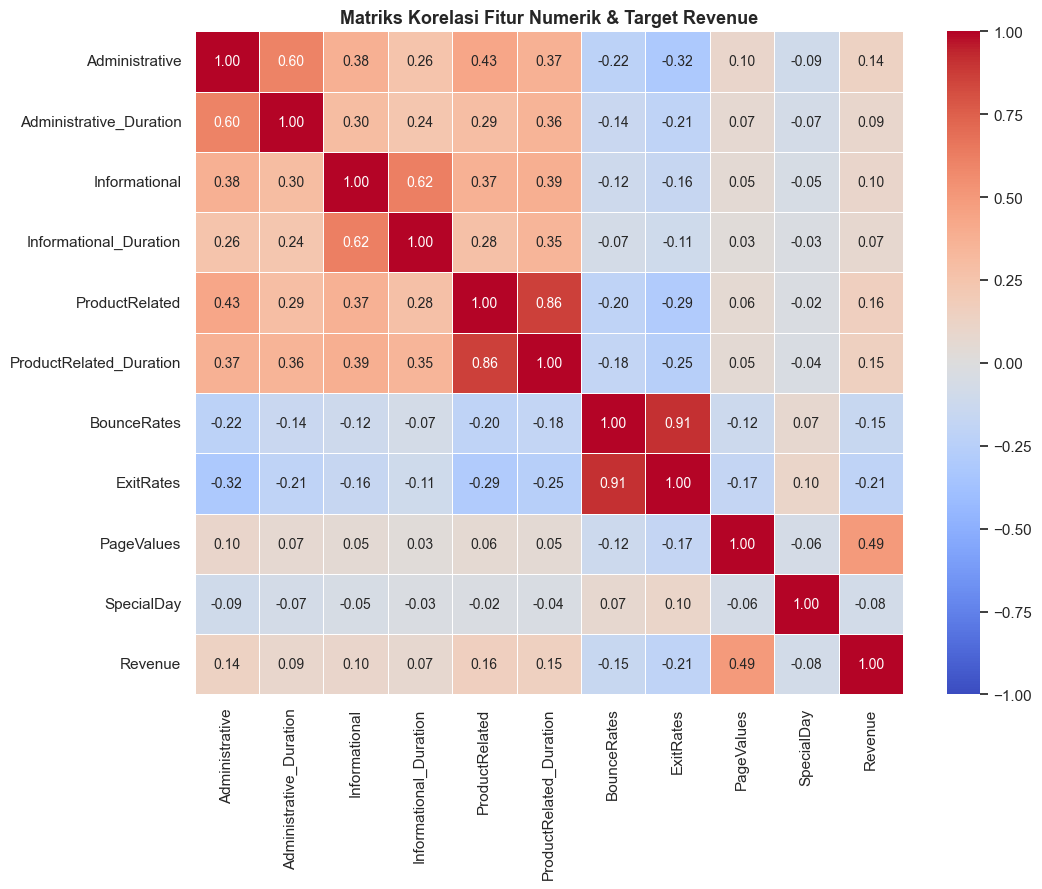

In [10]:
# Menghitung matriks korelasi Pearson antar fitur numerik
num_cols = [
    'Administrative', 'Administrative_Duration', 
    'Informational', 'Informational_Duration', 
    'ProductRelated', 'ProductRelated_Duration', 
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Revenue'
]

correlation_matrix = df[num_cols].corr()

# Visualisasi heatmap korelasi
plt.figure(figsize=(11, 9))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriks Korelasi Fitur Numerik & Target Revenue', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 3.7. Rangkuman Temuan Kunci EDA
1. **Fitur Paling Berpengaruh**: `PageValues` memiliki korelasi positif paling kuat terhadap `Revenue` ($r \approx 0.49$). Pengunjung dengan sesi yang melewati halaman bernilai tinggi hampir selalu berujung pada transaksi.
2. **Korelasi Multikolinearitas Tinggi**: `BounceRates` dan `ExitRates` memiliki korelasi positif linier sangat kuat ($r \approx 0.91$). Hal ini logis karena kedua metrik ini sama-sama mengukur kecenderungan pengguna meninggalkan situs.
3. **Pola Musiman (Seasonality)**: Bulan **November** mencatat volume sesi kunjungan dan volume transaksi pembelian paling tinggi dibanding bulan-bulan lain (diduga terkait periode promo belanja akhir tahun / Black Friday / 11.11).
4. **Tipe Pengunjung**: Pengunjung lama (*Returning Visitor*) menyumbang volume sesi terbanyak, namun persentase konversi (*conversion rate*) pengunjung baru (*New Visitor*) relatif cukup tinggi.


## 4. Data Cleaning (Pembersihan Data)

Pembersihan data dilakukan secara metodis sesuai standar praktikum data science, mencakup:
1. Pengecekan dan penanganan nilai kosong (*missing values*).
2. Deteksi dan penghapusan baris data kembar (*duplicated rows*), disimpan langsung kembali ke DataFrame `df`.
3. Deteksi serta penelaahan pencilan (*outliers*) menggunakan metode IQR.

---

### 4.1. Pemeriksaan Missing Values
Pemeriksaan dilakukan dengan fungsi `.isna().sum()` atau `.isnull().sum()`.


In [11]:
# 1. Cek jumlah missing value per kolom
print("Jumlah Missing Values per Kolom:")
print(df.isna().sum())

# Cek persentase missing value
print("\nPersentase Missing Values (%):")
print((df.isna().mean() * 100).round(2))


Jumlah Missing Values per Kolom:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Persentase Missing Values (%):
Administrative             0.0
Administrative_Duration    0.0
Informational              0.0
Informational_Duration     0.0
ProductRelated             0.0
ProductRelated_Duration    0.0
BounceRates                0.0
ExitRates                  0.0
PageValues                 0.0
SpecialDay                 0.0
Month                      0.0
OperatingSystems           0.0
Browser                    0

**Evaluasi Missing Value:**
Seluruh kolom memiliki 0 nilai kosong (*0 missing values*). Dataset ini sudah terisi lengkap dari sumber aslinya sehingga tidak memerlukan proses imputasi (mean/median/modus) maupun drop baris *missing*.


### 4.2. Deteksi & Penanganan Data Duplikat (*Duplicated Rows*)

**Alasan Wajib Hapus Duplikat:**
- **Distorsi Bobot**: Duplikasi data sesi memberikan bobot ganda (*pseudo-density*) yang tidak adil bagi profil sesi tertentu.
- **Mencegah Overfitting**: Menghindari model mempelajari sesi observasi berulang yang identik.
- **Konsistensi Statistik**: Memastikan ukuran sebaran dan tendensi sentral tidak terdistorsi.


In [12]:
# Cek ukuran dataset sebelum drop duplikat
print(f"Ukuran dataset sebelum pembersihan: {df.shape}")

# Menghitung jumlah baris duplikat
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat terdeteksi: {jumlah_duplikat}")

# Menghapus baris duplikat dan disimpan kembali ke DataFrame df
df = df.drop_duplicates().reset_index(drop=True)

# Cek ukuran dataset setelah drop duplikat
print(f"Ukuran dataset setelah pembersihan : {df.shape}")
print(f"Sisa baris duplikat                : {df.duplicated().sum()}")


Ukuran dataset sebelum pembersihan: (12330, 18)
Jumlah baris duplikat terdeteksi: 125
Ukuran dataset setelah pembersihan : (12205, 18)
Sisa baris duplikat                : 0


### 4.3. Deteksi & Analisis Outlier (Metode IQR)

Berdasarkan modul praktikum, deteksi pencilan dilakukan dengan menghitung rentang antar kuartil (*Interquartile Range* / IQR):
$$\text{IQR} = Q_3 - Q_1$$
$$\text{Batas Bawah} = Q_1 - 1.5 \times \text{IQR}$$
$$\text{Batas Atas} = Q_3 + 1.5 \times \text{IQR}$$


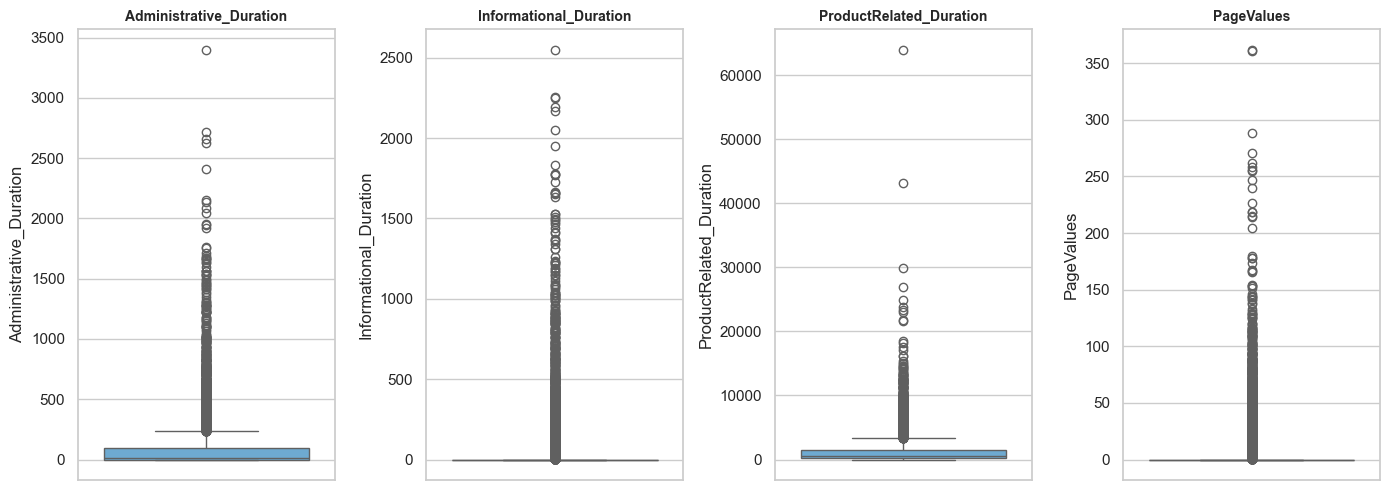

Ambang Batas Outlier Berdasarkan Metode IQR:
- Administrative_Duration  : Q1=    0.00 | Q3=   94.70 | IQR=   94.70 | Batas Atas=  236.75 | Outlier: 1149 baris
- Informational_Duration   : Q1=    0.00 | Q3=    0.00 | IQR=    0.00 | Batas Atas=    0.00 | Outlier: 2405 baris
- ProductRelated_Duration  : Q1=  193.00 | Q3= 1477.15 | IQR= 1284.15 | Batas Atas= 3403.39 | Outlier: 951 baris
- PageValues               : Q1=    0.00 | Q3=    0.00 | IQR=    0.00 | Batas Atas=    0.00 | Outlier: 2730 baris


In [13]:
# Visualisasi boxplot untuk mendeteksi outlier pada durasi dan page values
kolom_durasi = ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration', 'PageValues']

plt.figure(figsize=(14, 5))
for i, col in enumerate(kolom_durasi, 1):
    plt.subplot(1, 4, i)
    sns.boxplot(y=df[col], color='#5dade2')
    plt.title(col, fontsize=10, fontweight='bold')
    plt.tight_layout()

plt.show()

# Menghitung ambang batas outlier IQR secara numerik
print("Ambang Batas Outlier Berdasarkan Metode IQR:")
for col in kolom_durasi:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    bb = q1 - 1.5 * iqr
    ba = q3 + 1.5 * iqr
    outlier_count = ((df[col] < bb) | (df[col] > ba)).sum()
    print(f"- {col:25}: Q1={q1:8.2f} | Q3={q3:8.2f} | IQR={iqr:8.2f} | Batas Atas={ba:8.2f} | Outlier: {outlier_count} baris")


**Kebijakan Penanganan Outlier:**
- Pada data navigasi web e-commerce, nilai durasi penjelajahan yang sangat tinggi atau `PageValues` yang besar bukanlah akibat kesalahan alat ukur (*human error / sensor failure*), melainkan mencerminkan perilaku nyata pengunjung (*heavy users* / pembeli setia) yang berselancar secara mendalam sebelum melakukan transaksi bernilai besar.
- Menghapus observasi ini (*trimming*) akan menghilangkan informasi penting mengenai karakteristik pembeli aktual (*Revenue = True*).
- Oleh karena itu, data outlier dipertahankan pada DataFrame `df`, dan efek rentang nilainya yang besar akan dinormalisasi/distandarisasi pada tahap prapemrosesan menggunakan metode **StandardScaler**.


## 5. Data Preprocessing (Prapemrosesan Data)

Tahap prapemrosesan menyiapkan data ke dalam format matematis yang siap diterima oleh algoritma Machine Learning:
1. **Feature Engineering**: Membuat atribut turunan baru yang relevan dengan domain bisnis langsung pada DataFrame `df`.
2. **Categorical Encoding**: Mengubah tipe boolean ke biner integer, dan mengubah fitur kategorikal nominal menggunakan One-Hot Encoding (`pd.get_dummies`).
3. **Pemisahan Fitur & Target**: Memisahkan matriks fitur ($X$) dan vektor label ($y$).
4. **Train-Test Split**: Membagi data ke data latih (80%) dan data uji (20%) dengan *stratified sampling*.
5. **Feature Scaling**: Menstandarisasi skala fitur numerik menggunakan `StandardScaler`.

---

### 5.1. Feature Engineering (Pembuatan Fitur Baru)
Kita membentuk 2 fitur ringkasan sesi langsung pada DataFrame `df`:
- `Total_Pages`: Total keseluruhan halaman yang dikunjungi (`Administrative` + `Informational` + `ProductRelated`).
- `Total_Duration`: Total durasi waktu keseluruhan yang dihabiskan pengunjung di seluruh halaman web.


In [14]:
# Feature Creation langsung pada DataFrame df
df['Total_Pages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['Total_Duration'] = df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']

# Menampilkan 5 baris pertama fitur turunan
display(df[['Administrative', 'Informational', 'ProductRelated', 'Total_Pages', 'Total_Duration']].head())


,Administrative,Informational,ProductRelated,Total_Pages,Total_Duration
0,0,0,1,1,0.000000
1,0,0,2,2,64.000000
2,0,0,1,1,0.000000
3,0,0,2,2,2.666667
4,0,0,10,10,627.500000


### 5.2. Categorical Encoding (Pengkodean Kategorikal)

Sesuai aturan praktikum:
- **Fitur Boolean / Biner**: `Weekend` dan `Revenue` diubah langsung menjadi integer (0 dan 1).
- **Fitur Kategorikal Nominal**: `Month` dan `VisitorType` di-encode menggunakan **One-Hot Encoding** (`pd.get_dummies(..., drop_first=True)`).
- Menghindari penggunaan `LabelEncoder` pada fitur prediktor $X$ agar tidak memunculkan asumsi tingkatan matematis semu (*artificial ranking*).


In [15]:
# 1. Konversi fitur biner/boolean ke integer (0 dan 1) pada df
df['Weekend'] = df['Weekend'].astype(int)
df['Revenue'] = df['Revenue'].astype(int)

# 2. One-Hot Encoding untuk fitur nominal (Month dan VisitorType)
kolom_kategorikal = ['Month', 'VisitorType']
df = pd.get_dummies(df, columns=kolom_kategorikal, drop_first=True, dtype=int)

print(f"Dimensi DataFrame df setelah One-Hot Encoding: {df.shape}")
display(df.head())


Dimensi DataFrame df setelah One-Hot Encoding: (12205, 29)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Feb,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1


### 5.3. Pemisahan Fitur ($X$) dan Target ($y$)

In [16]:
# Memisahkan matriks fitur (X) dan target (y) dari DataFrame df
X = df.drop(columns=['Revenue'])
y = df['Revenue']

print(f"Dimensi Fitur (X): {X.shape}")
print(f"Dimensi Target (y): {y.shape}")


Dimensi Fitur (X): (12205, 28)
Dimensi Target (y): (12205,)


### 5.4. Pembagian Data Latih dan Uji (*Train-Test Split*)
Data dibagi dengan proporsi **80% data latih (*training set*)** dan **20% data uji (*test set*)**. Parameter `stratify=y` digunakan agar proporsi rasio ketidakseimbangan kelas target tetap seimbang di kedua subset.


In [17]:
# Membagi data train-test split (80:20) dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Ukuran X_train: {X_train.shape}")
print(f"Ukuran X_test : {X_test.shape}")
print(f"Ukuran y_train: {y_train.shape}")
print(f"Ukuran y_test : {y_test.shape}")

print("\nProporsi kelas target pada Data Latih (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nProporsi kelas target pada Data Uji (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))


Ukuran X_train: (9764, 28)
Ukuran X_test : (2441, 28)
Ukuran y_train: (9764,)
Ukuran y_test : (2441,)

Proporsi kelas target pada Data Latih (%):
Revenue
0    84.37
1    15.63
Name: proportion, dtype: float64

Proporsi kelas target pada Data Uji (%):
Revenue
0    84.35
1    15.65
Name: proportion, dtype: float64


### 5.5. Penskalaan Fitur Numerik (*Feature Scaling*)

**Alasan Ilmiah Pemilihan StandardScaler:**
- Fitur-fitur numerik memiliki perbedaan rentang skala yang drastis (contoh: `ProductRelated_Duration` mencapai ribuan detik, sedangkan `ExitRates` dan `BounceRates` berada pada rentang 0.0 s.d. 0.2).
- Penskalaan dengan **StandardScaler** mentransformasikan data agar memiliki nilai rata-rata (mean) = 0 dan variansi (std) = 1.
- StandardScaler lebih tahan (*robust*) terhadap outlier dibandingkan MinMaxScaler yang cenderung memampatkan mayoritas data ke rentang sempit.
- **Penting**: `fit_transform` hanya dilakukan pada `X_train`, sedangkan `X_test` hanya di-`transform` menggunakan parameter dari `X_train` untuk menghindari kebocoran data (*data leakage*).


In [18]:
# Daftar fitur numerik kontinu yang perlu distandarisasi
fitur_numerik = [
    'Administrative', 'Administrative_Duration', 
    'Informational', 'Informational_Duration', 
    'ProductRelated', 'ProductRelated_Duration', 
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay',
    'Total_Pages', 'Total_Duration'
]

# Inisialisasi StandardScaler
scaler = StandardScaler()

# Salinan fitur untuk penskalaan
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit pada train, transform pada train dan test
X_train_scaled[fitur_numerik] = scaler.fit_transform(X_train[fitur_numerik])
X_test_scaled[fitur_numerik] = scaler.transform(X_test[fitur_numerik])

print("Pratinjau data latih setelah distandarisasi (5 baris pertama):")
display(X_train_scaled[fitur_numerik].head())


Pratinjau data latih setelah distandarisasi (5 baris pertama):


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Total_Pages,Total_Duration
7469,1.689206,0.676238,0.381750,-0.243015,0.220868,-0.080395,-0.448703,-0.800192,1.665596,-0.311837,0.342413,-0.033316
11804,-0.699498,-0.458067,-0.397879,-0.243015,-0.046900,-0.158842,-0.448703,-0.739774,1.495448,-0.311837,-0.105739,-0.206000
3250,-0.699498,-0.458067,-0.397879,-0.243015,-0.426237,-0.408089,-0.448703,-0.287446,-0.315264,3.689185,-0.468529,-0.439738
204,-0.102322,-0.235218,-0.397879,-0.243015,-0.604748,-0.336795,-0.448703,-0.279507,-0.315264,-0.311837,-0.596572,-0.353406
4392,-0.699498,-0.458067,-0.397879,-0.243015,-0.359295,0.203501,-0.448703,-0.609743,-0.315264,-0.311837,-0.404507,0.133796


### 5.6. Ringkasan Kesiapan Data dalam DataFrame
Seluruh tahapan pembersihan dan prapemrosesan telah tersimpan secara terstruktur di memori dalam bentuk DataFrame (`df`, `X_train_scaled`, `X_test_scaled`, `y_train`, `y_test`) dan siap digunakan langsung pada tahap pemodelan klasifikasi.


In [19]:
# Menampilkan ringkasan akhir dimensi data di DataFrame
print("=" * 60)
print("RINGKASAN STATUS DATASET DI DATAFRAME:")
print("=" * 60)
print(f"1. DataFrame Utama (df)              : {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"2. Matriks Fitur Latih Terstandarisasi (X_train_scaled) : {X_train_scaled.shape}")
print(f"3. Matriks Fitur Uji Terstandarisasi   (X_test_scaled)  : {X_test_scaled.shape}")
print(f"4. Label Target Latih (y_train)      : {y_train.shape}")
print(f"5. Label Target Uji (y_test)         : {y_test.shape}")
print("=" * 60)
print("Data bersih dan terstandarisasi siap untuk tahap pemodelan Machine Learning!")


RINGKASAN STATUS DATASET DI DATAFRAME:
1. DataFrame Utama (df)              : 12205 baris, 29 kolom
2. Matriks Fitur Latih Terstandarisasi (X_train_scaled) : (9764, 28)
3. Matriks Fitur Uji Terstandarisasi   (X_test_scaled)  : (2441, 28)
4. Label Target Latih (y_train)      : (9764,)
5. Label Target Uji (y_test)         : (2441,)
Data bersih dan terstandarisasi siap untuk tahap pemodelan Machine Learning!
